In [1]:
%matplotlib inline
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D 
from matplotlib import gridspec
import matplotlib.colors as colors
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib import cm
from matplotlib.patches import Patch


import scanpy as sc


import seaborn as sns
import snapatac2 as snap

snap.__version__

plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.size'] = 14
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font for font in 'Liberation Sans, DejaVu Sans, Arial, Helvetica, Lucida Grande, Verdana, Geneva, Lucid, Avant Garde, sans-serif'.split(', ')] 
plt.rcParams['mathtext.fontset'] = 'stixsans'

plt.rcParams['axes.linewidth'] = 1
plt.rcParams['grid.linewidth'] = 1
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 6


/home/syyang/python_virtuenv/atac_tobias3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:

scanpy_colors = [    
    '#1f77b4',
    '#ff7f0e', 
    '#2ca02c',
    '#d62728', 
    '#9467bd', 
    '#8c564b', 
    '#e377c2', 
    '#bcbd22', 
    '#17becf', 
    '#c7c7c7', 
    '#ffbb78',
    '#98df8a']
scanpy_cluster = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11']
atac_scanpy_color_map = dict(zip(scanpy_cluster + ['Debris_or_doublet'], scanpy_colors + ['#000000']))
rna_scanpy_color_map = dict(zip(scanpy_cluster + ['no_rna_info'], scanpy_colors + ['#000000']))

## Load Union set barcodes that are not Debris or Doublets

In [ ]:
entropy_dir = '/mnt/hdd_bob/syy/adipose/atac/res/VIB_10xmultiome_2_WS3000F'
Union_cell_subdir = os.path.join(entropy_dir, '_cell_calling_comparison')

Union_cell_rna_cluster_file = os.path.join(Union_cell_subdir,  'Union_cell_3set_with_RNA_cluster.tsv')
Union_cell_rna_cluster_df = pd.read_csv(Union_cell_rna_cluster_file, sep='\t', index_col=0)
Union_cell_rna_cluster_df['atac_barcode'] = Union_cell_rna_cluster_df.index.map(lambda x: x + '-1') 

union_cell_noDebrisDoublet_cluster_file = os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'snap_cluster_unioncells_noDebrisDoublets.tsv')

union_cell_noDebrisDoublet_cluster_df = pd.read_csv(union_cell_noDebrisDoublet_cluster_file, sep='\t', index_col=0)

data_filter = sc.read_h5ad(os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'binnedGenome_unioncells_noDebrisDoublets.h5ad'))

data_filter.obs['leiden_RNA_scVI'] = data_filter.obs.index.map(Union_cell_rna_cluster_df['leiden_RNA_scVI']).fillna('no_rna_info')
data_filter.obs['Entropy'] = data_filter.obs.index.map(Union_cell_rna_cluster_df['Entropy'])


In [5]:
data_filter

AnnData object with n_obs × n_vars = 2286 × 6062095
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'rna_pass_CR', 'atac_pass_CR', 'atac_pass_entropy', 'atac_pass_archr_TSS', '_2set_identified_by_atac_SC', '_2set_identified_by_atac_ST', '_3set_identified_by_atac', 'DNA_debris', 'amulet_doublet_atac', 'tsse', 'leiden', 'filtered_leiden', 'leiden_RNA_scVI'
    var: 'count', 'selected'
    uns: 'DNA_debris_colors', 'TSS_profile', '_3set_identified_by_atac_colors', 'amulet_doublet_atac_colors', 'filtered_distance', 'filtered_leiden_colors', 'filtered_spectral_eigenvalue', 'frac_overlap_TSS', 'leiden_colors', 'library_tsse', 'reference_sequences', 'rna_pass_CR_colors', 'spectral_eigenvalue'
    obsm: 'X_spectral', 'X_umap', 'filtered_X_spectral', 'filtered_X_umap', 'fragment_paired'
    obsp: 'distances', 'filtered_distance'

## Vis

... storing 'leiden_RNA_scVI' as categorical


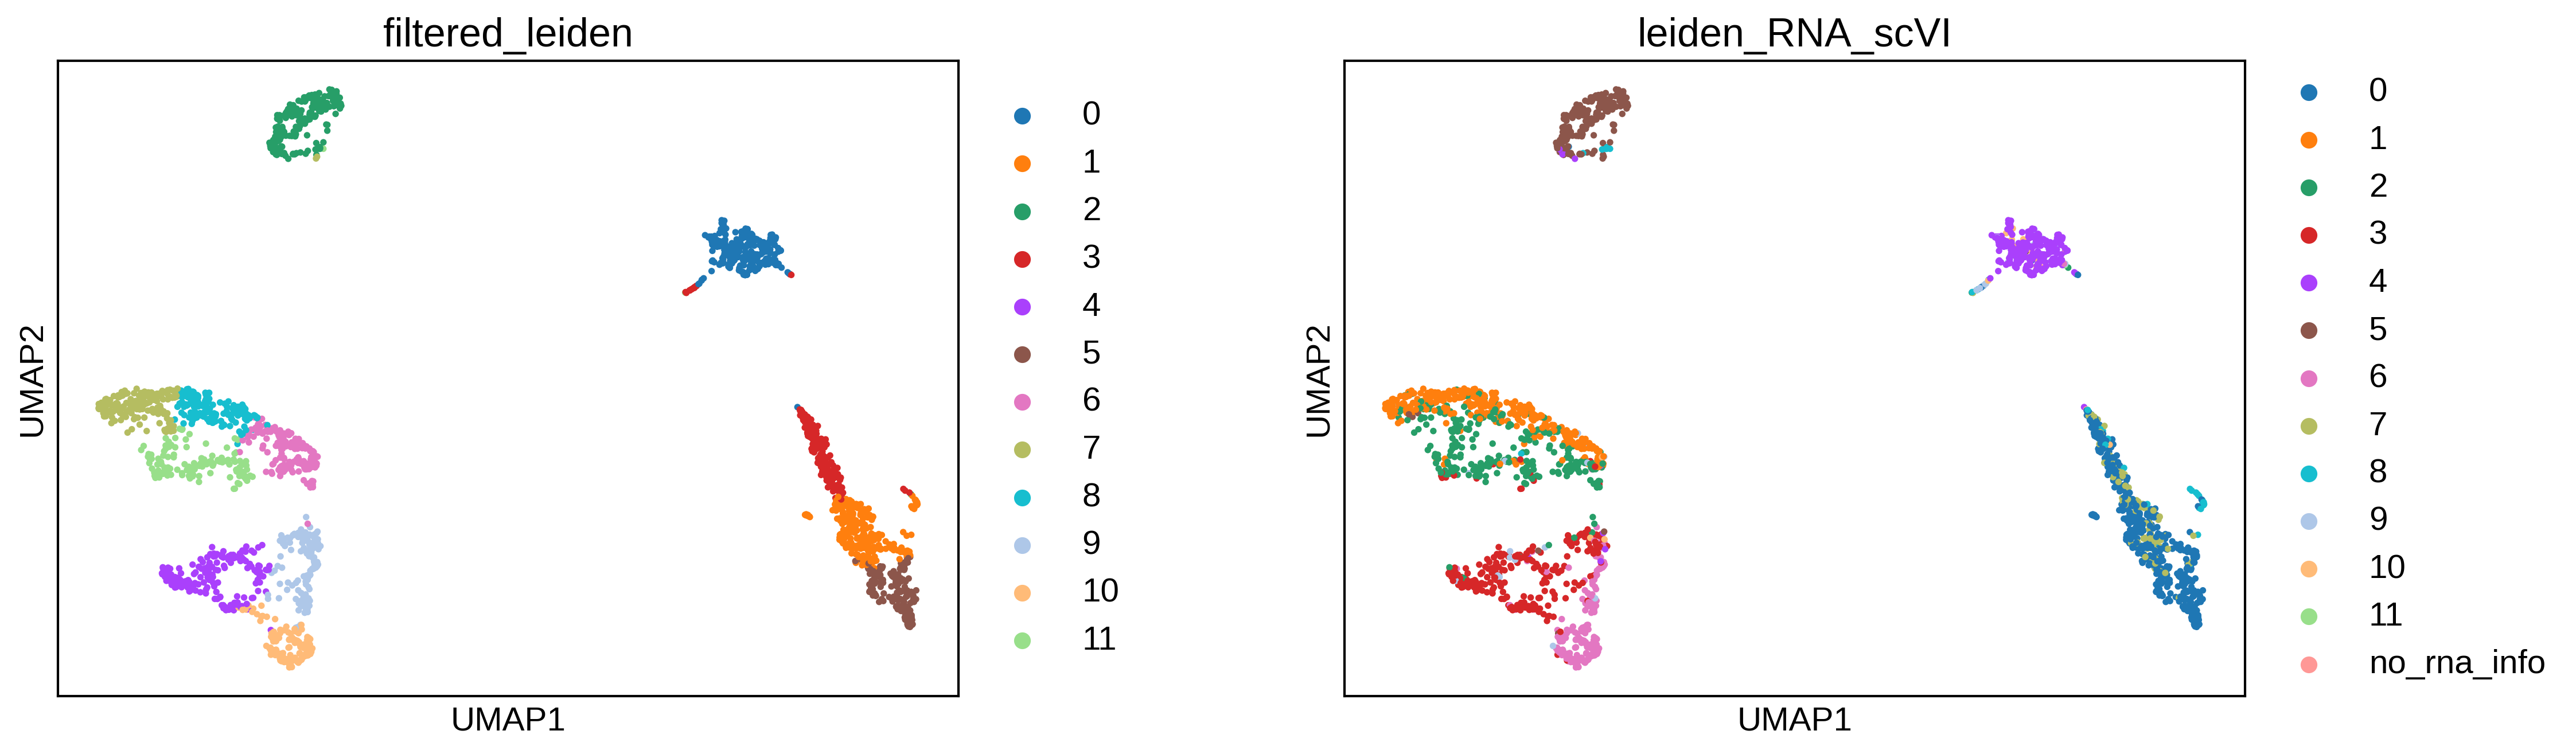

In [6]:
ax = sc.pl.embedding(data_filter, basis='filtered_X_umap', color=['filtered_leiden',  'leiden_RNA_scVI', ], s=30, ncols=2, wspace=0.3,
                     show=False)
for a in ax:
    # a.tick_params(axis='both', which='major', labelsize=12)    
    a.set_xlabel('UMAP1',)
    a.set_ylabel('UMAP2',)

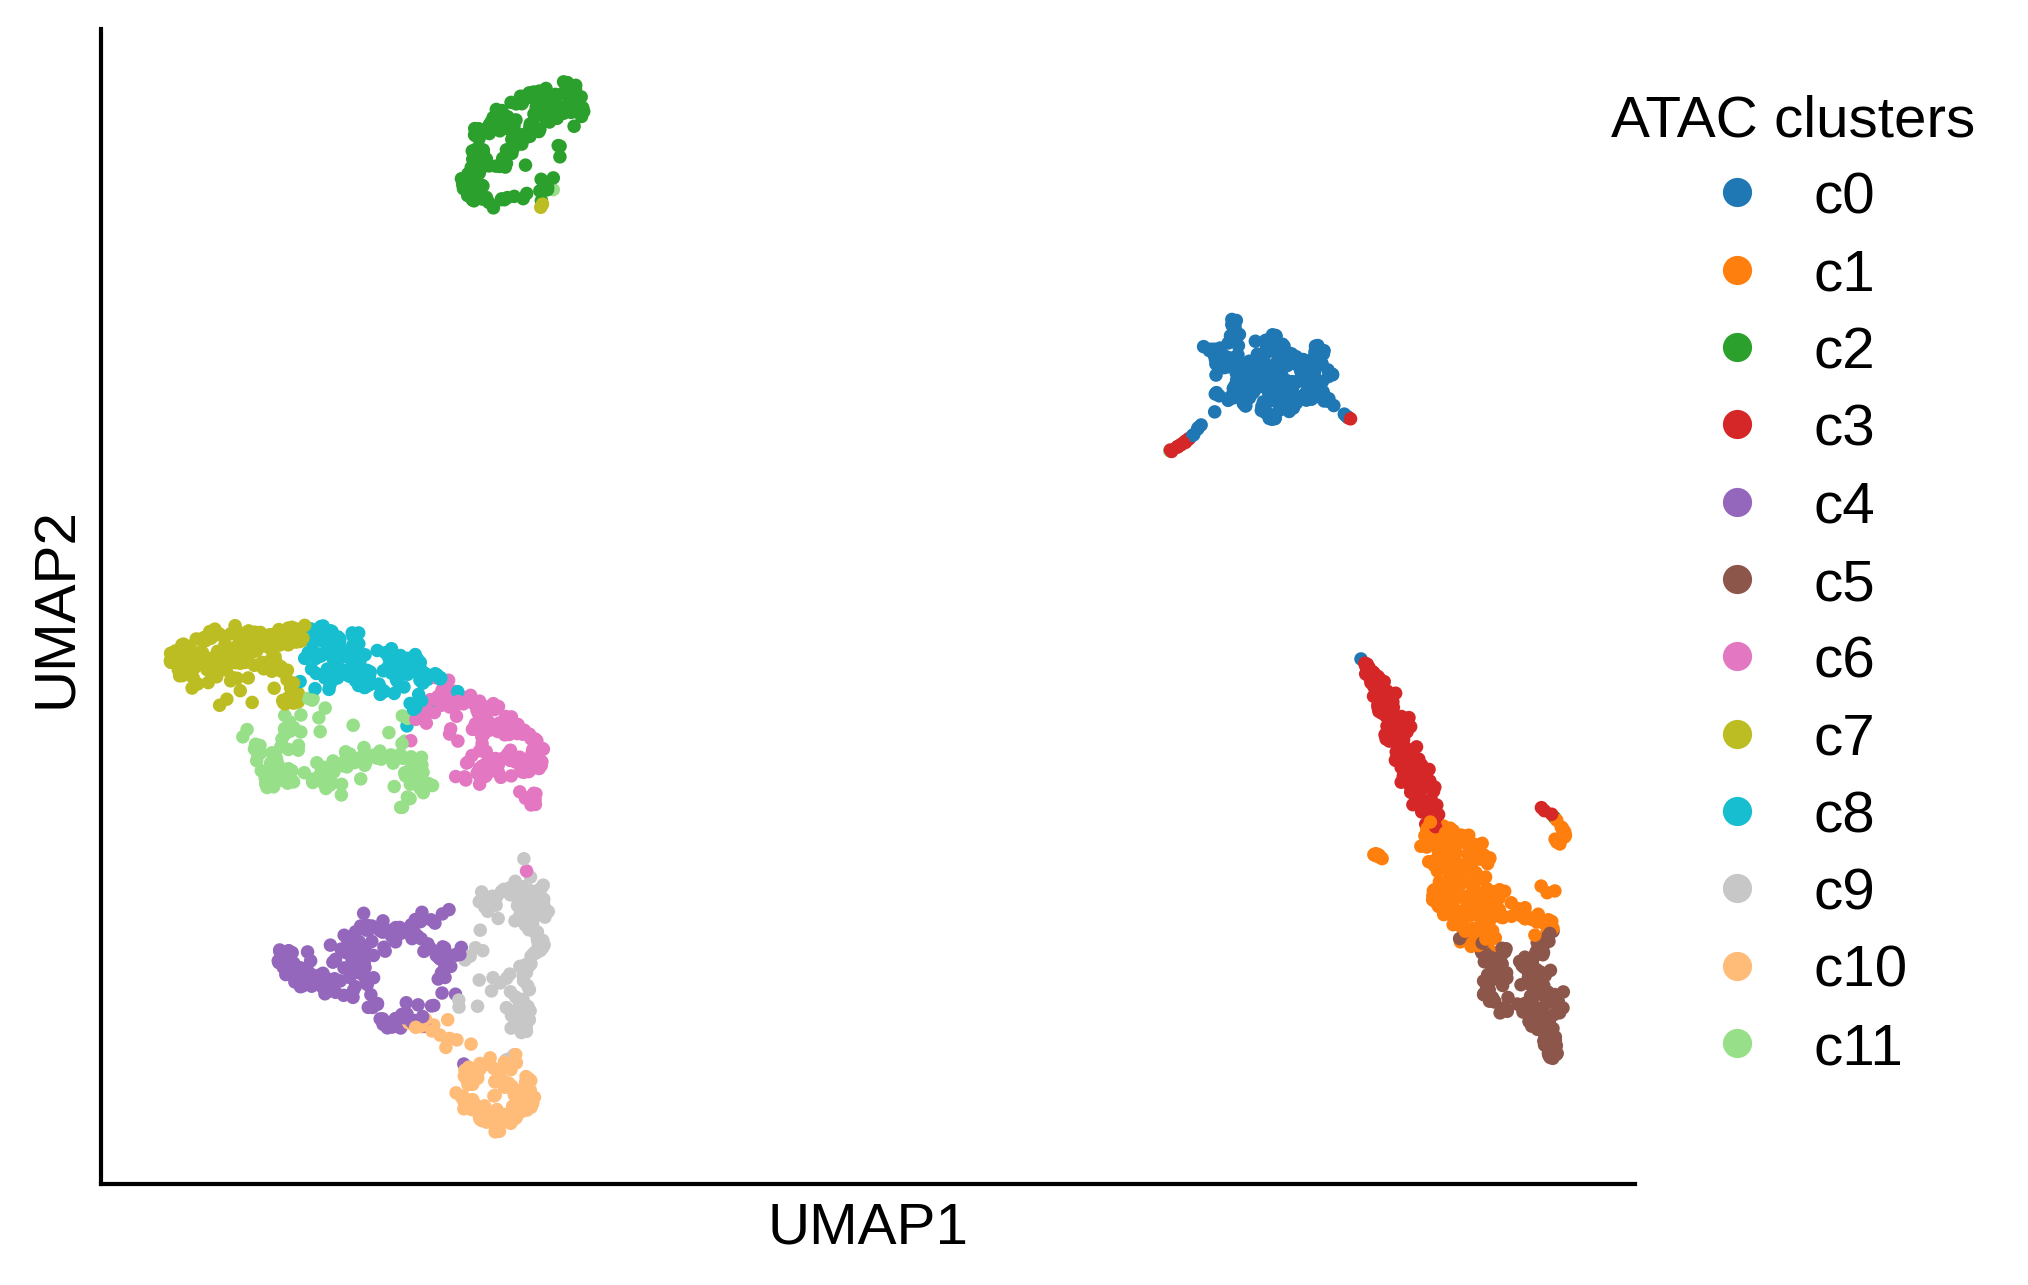

In [7]:
fig, ax = plt.subplots(1, figsize=(6.6, 5))
_ = ax.scatter(data_filter.obsm['filtered_X_umap'][:, 0], data_filter.obsm['filtered_X_umap'][:, 1], 
               s=5, c=data_filter.obs['filtered_leiden'].map(atac_scanpy_color_map))
ax.tick_params(axis='both', which='major', bottom=False, labelbottom=False, left=False, labelleft=False)
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

handles = [Line2D([0], [0], linewidth=0, marker='o', color=atac_scanpy_color_map[c], label=f'c{c}') for c in data_filter.obs['filtered_leiden'].cat.categories]
ax.legend(handles=handles, frameon=False, loc='upper left', bbox_to_anchor=(0.95, 0.99), title='ATAC clusters', labelspacing=0.4, handletextpad=0.3)
for edge in ['top', 'right']:
    ax.spines[edge].set_visible(False)

fig.savefig(os.path.join(os.getcwd(), '_figures', 'fig5_p3.png'), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(os.getcwd(), '_figures', 'fig5_p3.pdf'))

Text(0, 0.5, 'UMAP2')

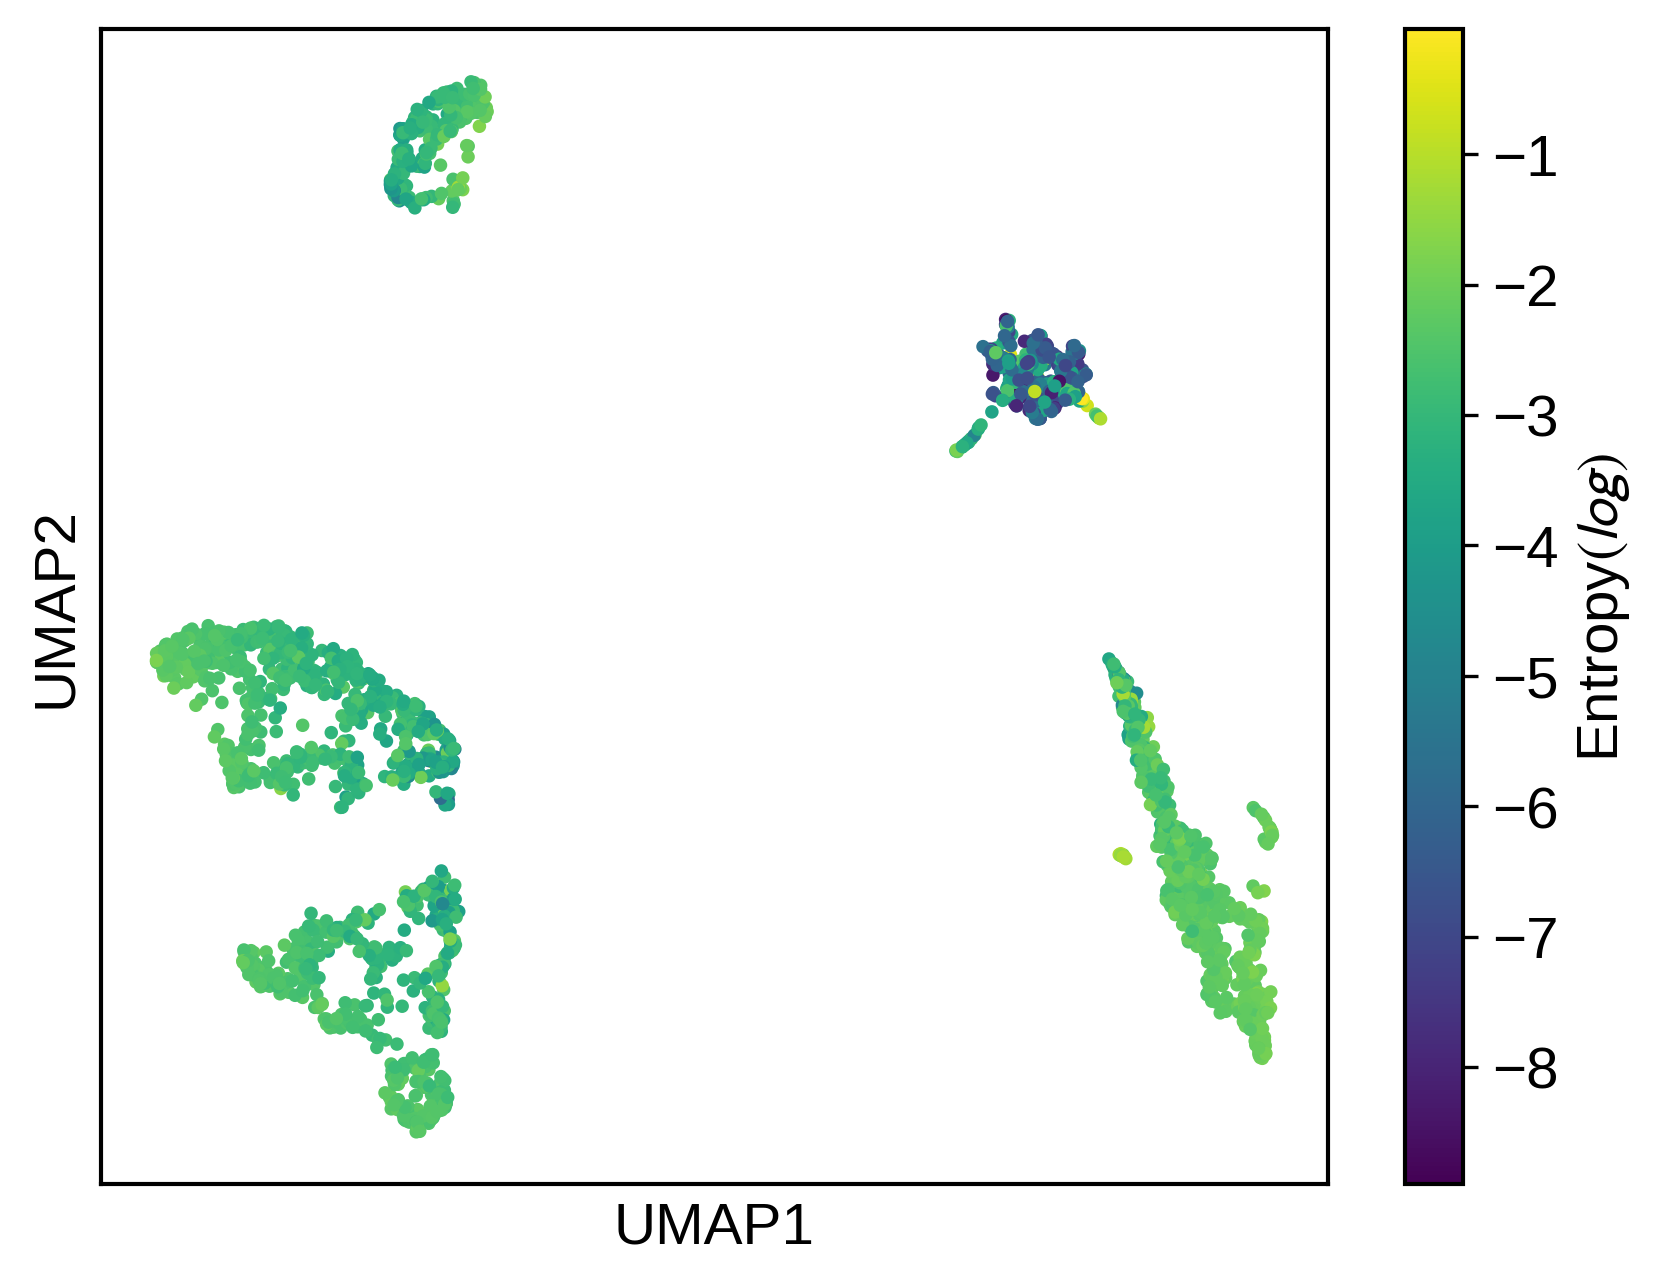

In [12]:

fig, ax = plt.subplots(1, figsize=(6.6, 5))
_ = ax.scatter(data_filter.obsm['filtered_X_umap'][:, 0], data_filter.obsm['filtered_X_umap'][:, 1], 
               s=5, c=np.log2(data_filter.obs['Entropy']))
ax.tick_params(axis='both', which='major', bottom=False, labelbottom=False, left=False, labelleft=False)
fig.colorbar(ax.collections[0], ax=ax, label='Entropy$(log)$')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')


## Load Union set barcodes 

In [14]:
data = sc.read_h5ad(os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'binnedGenome_all_unioncells.h5ad'))

data.obs['leiden_RNA_scVI'] = data.obs.index.map(Union_cell_rna_cluster_df['leiden_RNA_scVI']).fillna('no_rna_info')
data.obs['filtered_leiden'] = data.obs.index.map(union_cell_noDebrisDoublet_cluster_df['filtered_leiden']).fillna('Debris_or_doublet')

data.obs['debris_doublets_flag'] = data.obs.apply(lambda row: 
    'debrisNdoublet' if row['DNA_debris'] == 'YES' and row['amulet_doublet_atac'] == True \
        else ('doublets' if row['amulet_doublet_atac'] == True \
            else ('Debris' if row['DNA_debris'] == 'YES' else 'clean')), axis=1)

In [19]:
h5_rna_union_file = os.path.join(Union_cell_subdir, 'Union_3set_rna.h5ad')
h5_rna_union = sc.read_h5ad(h5_rna_union_file)
h5_rna_union.obs['atac_bc'] = h5_rna_union.obs['atac_barcodes'].map(lambda x: x + '-1')
h5_rna_union

/home/syyang/python_virtuenv/atac_tobias3.13/lib/python3.13/site-packages/anndata/_core/anndata.py:1808: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 2381 × 36601
    obs: 'rna_barcodes', 'atac_barcodes', 'total_RNA_UMI', 'total_RNA_UMI_log', 'n_genes_by_RNA_counts', 'N_MT_counts', 'MT%', 'atac_bc'
    var: 'gene_ids', 'feature_types', 'genome'

In [18]:
h5_rna_union.obs.head(2)

,rna_barcodes,atac_barcodes,total_RNA_UMI,total_RNA_UMI_log,n_genes_by_RNA_counts,N_MT_counts,MT%
AAACAGCCAGGCTACT-1,AAACAGCCAGGCTACT,ACAGCGGGTTTGTAGC,3931.0,8.276903,1772,519.0,13.202747
AAACATGCAAGGATTA-1,AAACATGCAAGGATTA,CATTTAGGTAACAGCA,3566.0,8.179481,1689,401.0,11.245092


In [21]:
rna_col_list = ['total_RNA_UMI', 'n_genes_by_RNA_counts', 'N_MT_counts']
for col in rna_col_list:
    h5_rna_union.obs[col] = h5_rna_union.obs[col].fillna(0)

for col in rna_col_list:
    data.obs[col] = data.obs.index.map(h5_rna_union.obs.set_index('atac_bc')[col]).fillna(np.nan)

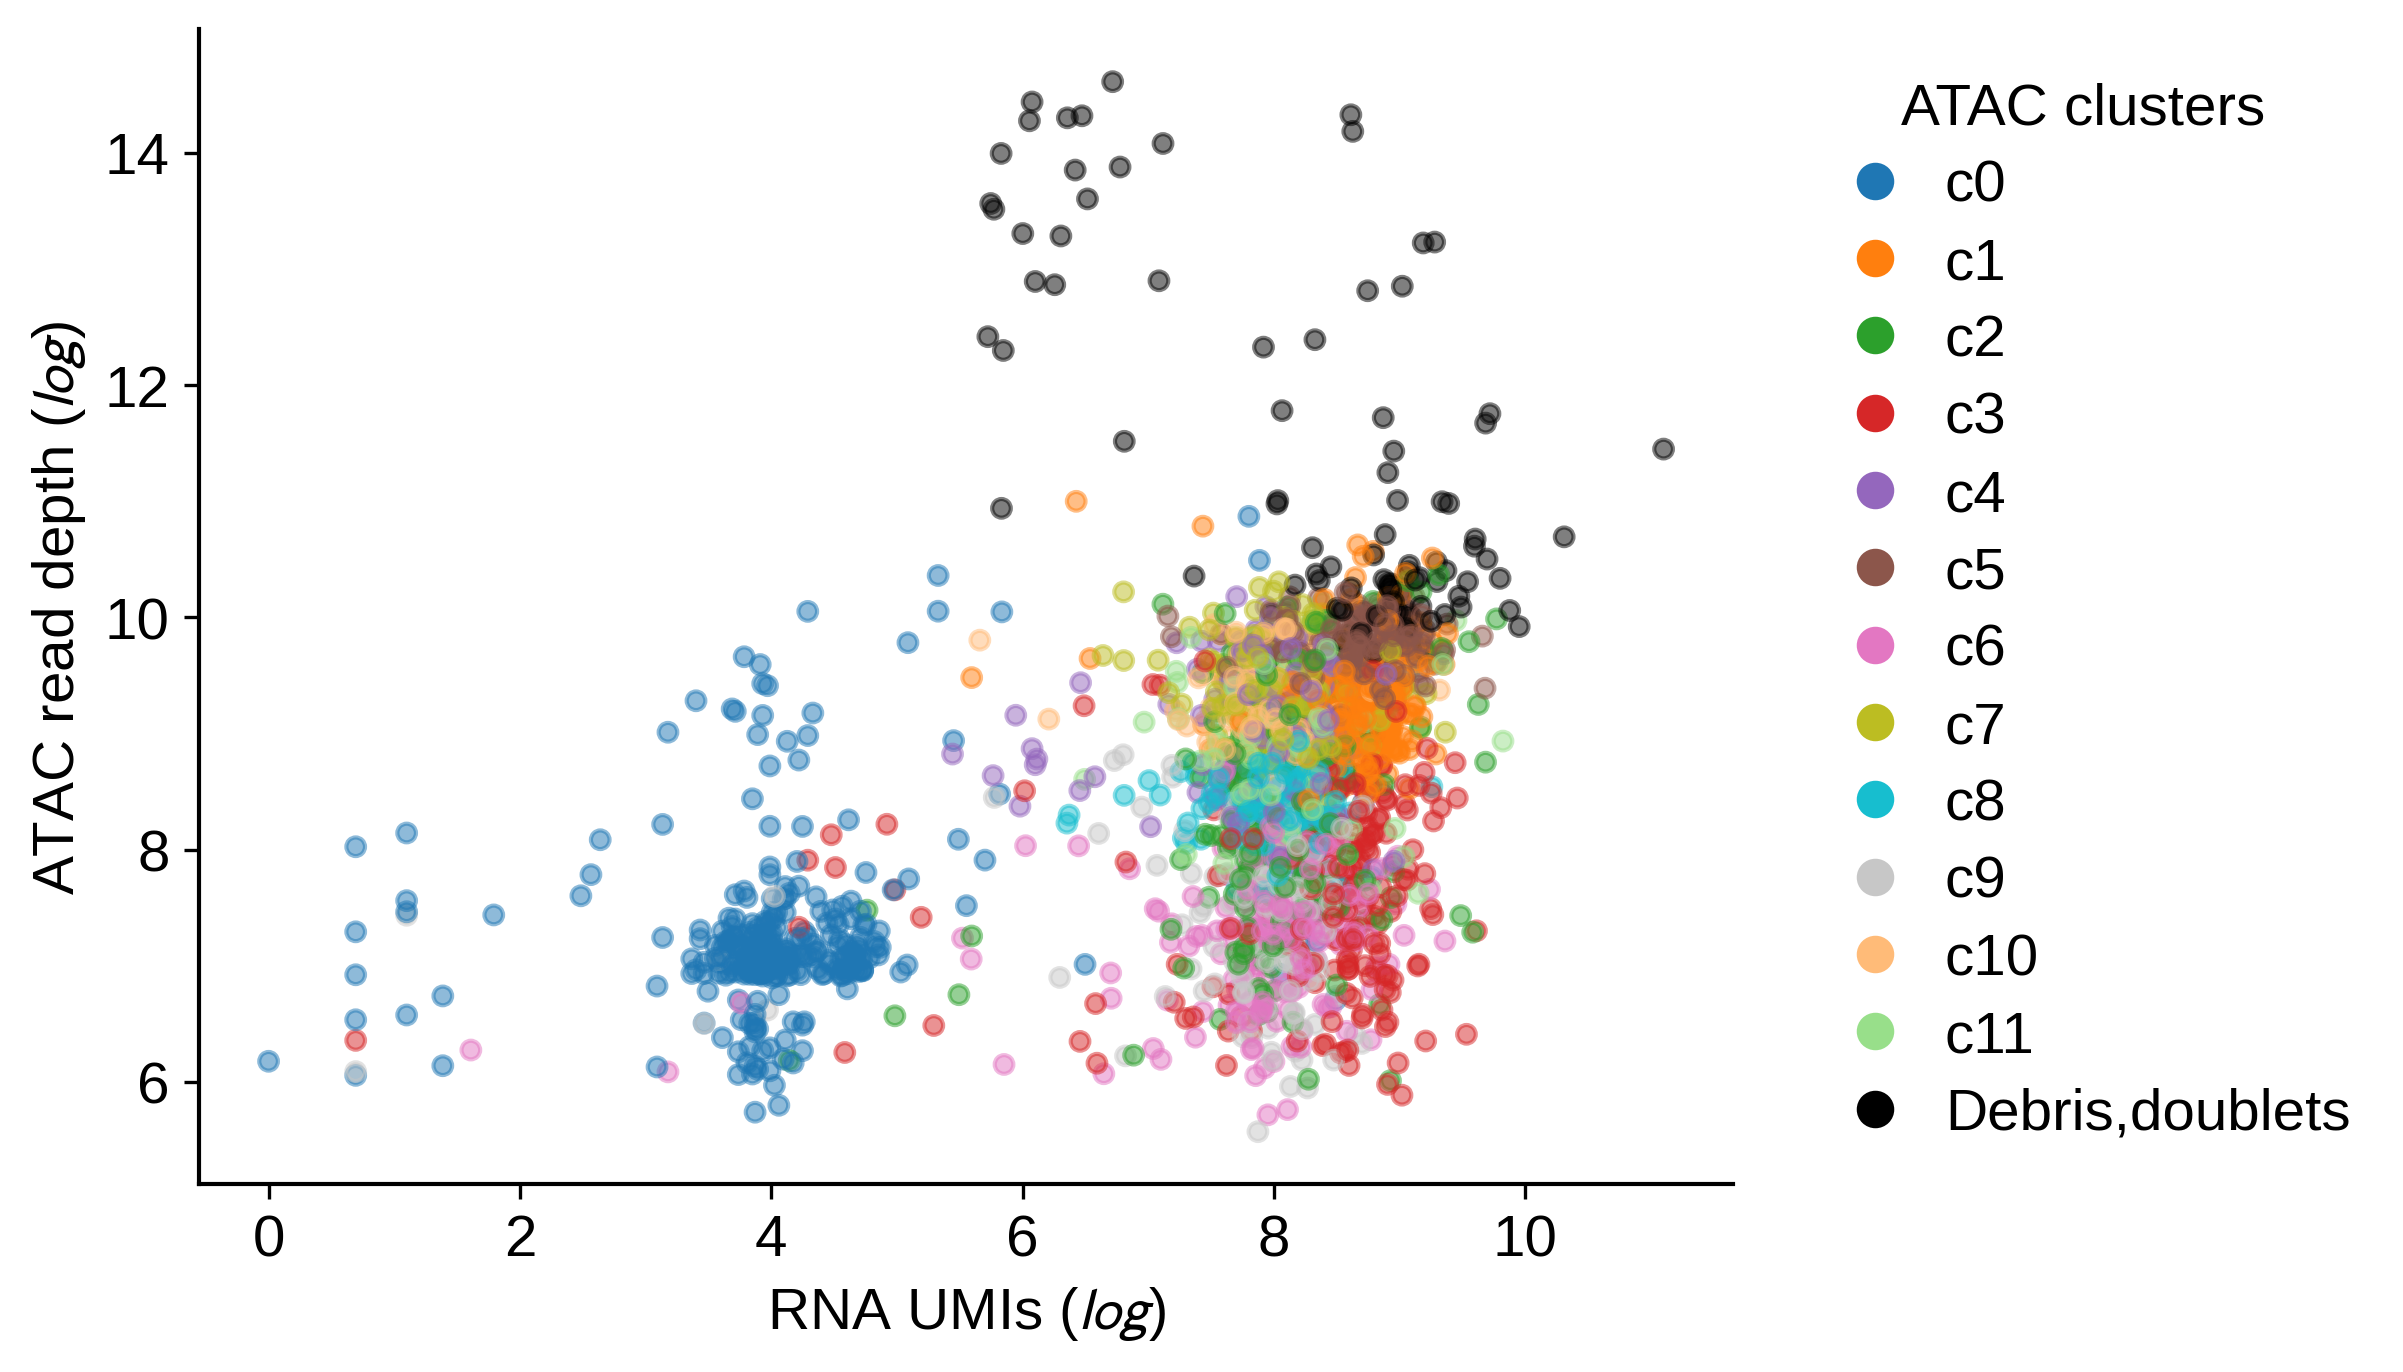

In [23]:
fig, ax = plt.subplots(figsize=(6.6, 5))
_ = ax.scatter(np.log1p(data.obs['total_RNA_UMI']), np.log1p(data.obs['n_fragment']), 
               c=data.obs['filtered_leiden'].map(lambda x: str(x).split('.')[0]).map(atac_scanpy_color_map),
               s=20, alpha=0.5)
ax.set_xlabel('RNA UMIs ($log$)')
ax.set_ylabel('ATAC read depth ($log$)')

atac_clusters = scanpy_cluster + ['Debris_or_doublet'] 
cluster_label = [f"c{cluster}" for cluster in scanpy_cluster ] + ['Debris,doublets']
cluster_label_map = dict(zip(atac_clusters, cluster_label))

handles=[Line2D([0], [0], marker='o', linewidth=0, markersize=8,color=atac_scanpy_color_map[cluster], label=cluster_label_map[cluster]) for cluster in atac_clusters]
ax.legend(handles=handles, frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left', title='ATAC clusters', labelspacing=0.4, handletextpad=0.2)
for edge in ['top', 'right']:
    ax.spines[edge].set_visible(False)

fig.savefig(os.path.join(os.getcwd(), '_figures', 'fig5_p4.png'), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(os.getcwd(), '_figures', 'fig5_p4.pdf'))

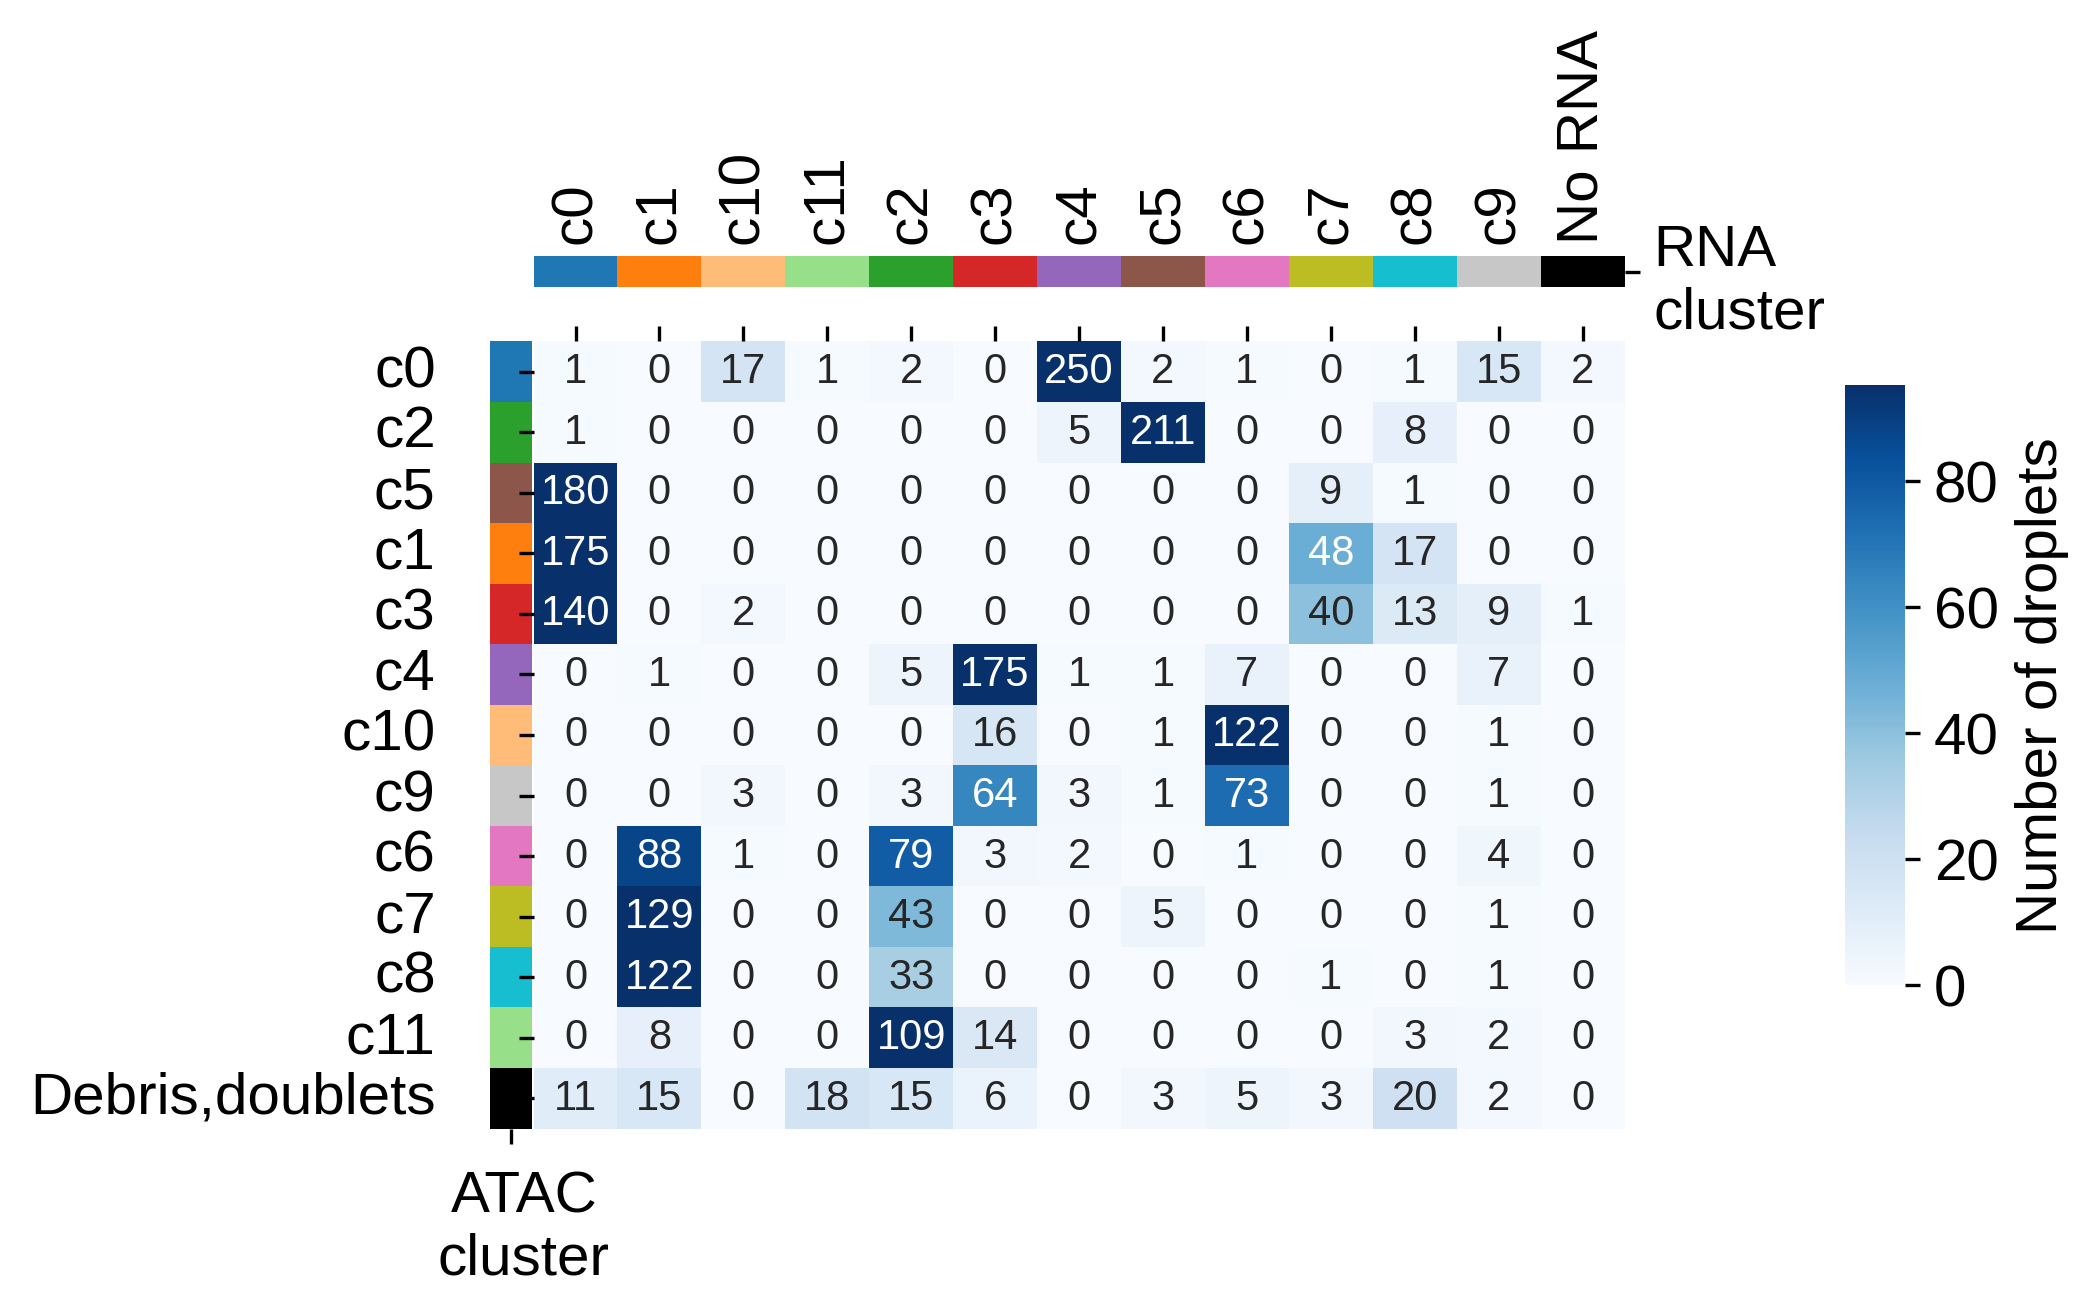

In [26]:
data.obs['filtered_leiden_mod'] = data.obs['filtered_leiden'].map(lambda x: str(x).split('.')[0]) # to simplify the labels 
data.obs['leiden_RNA_scVI_mod'] = data.obs['leiden_RNA_scVI'].map(lambda x: str(x)) 

correlation_mat = data.obs.groupby([ 'filtered_leiden_mod',  'leiden_RNA_scVI_mod']).size().unstack(fill_value=0)
correlation_mat.index.name = None
correlation_mat.columns.name = None
correlation_mat_index = correlation_mat.index.astype(str)
correlation_mat_columns = correlation_mat.columns.astype(str)


col_colors = pd.DataFrame({
    'RNA\ncluster': correlation_mat.columns.map(rna_scanpy_color_map),
    #'': correlation_mat.columns.map(rna_scanpy_color_map),
}, index= correlation_mat_columns)
row_colors = pd.DataFrame({
    # 'ATAC\ncluster': correlation_mat.index.map(atac_scanpy_color_map),
    '': correlation_mat.index.map(atac_scanpy_color_map),
}, index=correlation_mat_index)

# Rename 
correlation_mat.columns = ["No RNA" if i == "no_rna_info" else f"c{i}" for i in correlation_mat_columns]
correlation_mat.index = ["Debris,doublets" if i == "Debris_or_doublet" else f"c{i}" for i in correlation_mat_index]
col_colors.index = ["No RNA" if i == "no_rna_info" else f"c{i}" for i in correlation_mat_columns]
row_colors.index = ["Debris,doublets" if i == "Debris_or_doublet" else f"c{i}" for i in correlation_mat_index]

c_sd = correlation_mat.values.std()
c_mean = correlation_mat.values.mean()
c_min = np.max((c_mean - 2*c_sd, 0))
c_max = c_mean + 2*c_sd
c_center = 0.5 * (c_min + c_max)

g = sns.clustermap(correlation_mat, col_colors=col_colors, row_colors=row_colors, 
                   col_cluster=False, 
                   cmap='Blues', annot=True, fmt='d', xticklabels=True, yticklabels=True,
                   cbar_pos=(0.86, 0.3, 0.03, 0.4), 
                cbar_kws={'label': 'Number of droplets'}, annot_kws={"size": 10},
                vmin = c_min, vmax = c_max,
                center = c_center,
                figsize=(6.6, 5))
g.ax_row_dendrogram.set_visible(False) # Hide Row tree
g.ax_col_dendrogram.set_visible(False) # Hide Column tree


g.ax_heatmap.yaxis.tick_left()
g.ax_heatmap.yaxis.set_label_position("left")

g.ax_heatmap.xaxis.tick_top()
g.ax_heatmap.xaxis.set_label_position("top")

g.ax_heatmap.tick_params(axis='y', pad=20)
g.ax_heatmap.tick_params(axis='x', pad=20, rotation=90)

g.ax_row_colors.text(0.8, -.2, 'ATAC\ncluster', 
                     transform=g.ax_row_colors.transAxes, 
                     rotation=0, 
                     ha='center', 
                     va='bottom',)

g.savefig(os.path.join(os.getcwd(), '_figures', 'fig5_p5.png'), bbox_inches='tight', dpi=300)
g.savefig(os.path.join(os.getcwd(), '_figures', 'fig5_p5.pdf'), bbox_inches='tight')